# Scorecard WoE con datos observados de tarjetas: benchmark UCI

## Decisión y alcance
¿Puede un scorecard reproducible discriminar impago del siguiente mes en una muestra histórica de tarjetas? Este caso usa datos observados de Taiwán correspondientes a 2005, **no** una cartera colombiana ni decisiones de originación. Una partición aleatoria permite ilustrar estimación fuera de muestra en el mismo corte; no sustituye validación fuera de tiempo ni institucional.

## Fuente y diseño
[Yeh, 2009, Default of Credit Card Clients, UCI](https://doi.org/10.24432/C55S3H), 30.000 clientes, licencia [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Los estados de pago son históricos y la etiqueta corresponde al impago del mes siguiente. Seleccionamos `LIMIT_BAL`, `PAY_0`, `PAY_2`, `PAY_3` y `PAY_4` para un caso de seguimiento de cuentas existentes; excluimos identificador, edad, sexo, educación y estado civil. Las fechas de disponibilidad y políticas del dataset no se pueden auditar individualmente. Separamos 75 % entrenamiento y 25 % prueba por cliente mediante muestra aleatoria estratificada, semilla 42. No seleccionar hiperparámetros observando la muestra de prueba.

In [1]:
from pathlib import Path
import hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, log_loss
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'03-financial-risk').is_dir())
p=root/'03-financial-risk/01-credit-risk/credit-risk-products/scorecard-logistico-woe/observed-uci350/data/default-of-credit-card-clients.xls'
expected='30c6be3abd8dcfd3e6096c828bad8c2f011238620f5369220bd60cfc82700933'
actual=hashlib.sha256(p.read_bytes()).hexdigest(); assert actual==expected, 'Archivo no coincide con la fuente registrada'
df=pd.read_excel(p,header=1); features=['LIMIT_BAL','PAY_0','PAY_2','PAY_3','PAY_4']; target='default payment next month'
assert len(df)==30000 and df.ID.is_unique and df[target].isin([0,1]).all()
assert df[features+[target]].notna().all().all()
print('Archivo SHA-256:',actual,'| Registros:',len(df),'| tasa observada:',round(df[target].mean(),4))
df[features+[target]].describe().round(2)

Archivo SHA-256: 30c6be3abd8dcfd3e6096c828bad8c2f011238620f5369220bd60cfc82700933 | Registros: 30000 | tasa observada: 0.2212


,LIMIT_BAL,PAY_0,PAY_2,PAY_3,PAY_4,default payment next month
count,30000.00,30000.00,30000.00,30000.00,30000.00,30000.00
mean,167484.32,-0.02,-0.13,-0.17,-0.22,0.22
std,129747.66,1.12,1.20,1.20,1.17,0.42
min,10000.00,-2.00,-2.00,-2.00,-2.00,0.00
25%,50000.00,-1.00,-1.00,-1.00,-1.00,0.00
50%,140000.00,0.00,0.00,0.00,0.00,0.00
75%,240000.00,0.00,0.00,0.00,0.00,0.00
max,1000000.00,8.00,8.00,8.00,8.00,1.00


## WoE e información
Los puntos de corte por cuantiles y las proporciones se aprenden **solo en entrenamiento**. Para un intervalo $b$, con suavizado $a=0,5$, $WoE_b=\log[(G_b+a)/(G+aK)]-\log[(B_b+a)/(B+aK)]$. $G$ son pagos sin impago y $B$ impagos; $K$ es el número de intervalos. Las clases de pago discretas pueden producir menos de cinco intervalos. Este estimador usa el mismo entrenamiento para WoE y logit; su desempeño de entrenamiento es optimista y el test se reserva para evaluación.

In [2]:
train,test=train_test_split(df,test_size=.25,random_state=42,stratify=df[target])
assert set(train.ID).isdisjoint(set(test.ID))
print('Entrenamiento:',len(train),'| Prueba:',len(test),'| prevalencia prueba:',round(test[target].mean(),4))
def fit_woe(data,column):
    _,edges=pd.qcut(data[column],q=5,retbins=True,duplicates='drop')
    if len(edges)<3: raise ValueError('Se requieren al menos dos intervalos: '+column)
    edges[0]=-np.inf; edges[-1]=np.inf
    bins=pd.cut(data[column],edges,labels=False,include_lowest=True)
    grouped=pd.DataFrame({'bin':bins,'bad':data[target]}).groupby('bin',observed=True).bad.agg(['count','sum']).reindex(range(len(edges)-1),fill_value=0)
    bad=grouped['sum'].to_numpy(); good=grouped['count'].to_numpy()-bad; k=len(good)
    pg=(good+.5)/(good.sum()+.5*k); pb=(bad+.5)/(bad.sum()+.5*k)
    woe=np.log(pg/pb); iv=float(((pg-pb)*woe).sum())
    return edges,woe,iv,grouped
models={c:fit_woe(train,c) for c in features}
def transform(data):
    out=pd.DataFrame(index=data.index)
    for c,(edges,woe,iv,counts) in models.items():
        bins=pd.cut(data[c],edges,labels=False,include_lowest=True)
        if bins.isna().any(): raise ValueError('Bin no asignado: '+c)
        out[c]=woe[bins.astype(int).to_numpy()]
    return out
Xtrain=transform(train);Xtest=transform(test)
pd.DataFrame([{'variable':c,'intervalos':len(m[1]),'IV_entrenamiento':m[2]} for c,m in models.items()]).round(4)

Entrenamiento: 22500 | Prueba: 7500 | prevalencia prueba: 0.2212


,variable,intervalos,IV_entrenamiento
0,LIMIT_BAL,5,0.1671
1,PAY_0,4,0.8750
2,PAY_2,3,0.5494
3,PAY_3,3,0.4166
4,PAY_4,3,0.3577


## Modelo y evaluación retenida
La regresión logística produce probabilidades estimadas. En prueba presentamos AUC, Gini = 2 AUC − 1, KS, Brier y pérdida logarítmica. La calibración se resume por deciles de score de prueba, que aquí sirven para describir esta muestra y no definen bandas fijas para monitoreo futuro. Las métricas no prueban capacidad causal o aprobación regulatoria.

In [3]:
model=LogisticRegression(max_iter=1000,random_state=42).fit(Xtrain,train[target]); y=test[target].to_numpy(); prob=model.predict_proba(Xtest)[:,1]
fpr,tpr,_=roc_curve(y,prob); auc=roc_auc_score(y,prob)
metrics={'n_prueba':len(y),'eventos':int(y.sum()),'auc':auc,'gini':2*auc-1,'ks':float(np.max(tpr-fpr)),'brier':brier_score_loss(y,prob),'log_loss':log_loss(y,prob)}
print(pd.Series(metrics).round(4).to_string())
cal=pd.DataFrame({'pd':prob,'evento':y});cal['banda']=pd.qcut(cal.pd,10,duplicates='drop');calibration=cal.groupby('banda',observed=True).agg(n=('evento','size'),eventos=('evento','sum'),probabilidad_media=('pd','mean'),tasa_observada=('evento','mean'))
calibration.round(4)

n_prueba    7500.0000
eventos     1659.0000
auc            0.7432
gini           0.4863
ks             0.3941
brier          0.1399
log_loss       0.4467


,n,eventos,probabilidad_media,tasa_observada
banda,,,,
"(0.0883, 0.106]",1178,120,0.0989,0.1019
"(0.106, 0.108]",494,42,0.1076,0.0850
"(0.108, 0.118]",755,76,0.1166,0.1007
"(0.118, 0.135]",886,125,0.1279,0.1411
"(0.135, 0.139]",627,76,0.1384,0.1212
"(0.139, 0.161]",1180,203,0.1585,0.1720
"(0.161, 0.182]",270,43,0.1752,0.1593
"(0.182, 0.262]",642,172,0.2258,0.2679
"(0.262, 0.587]",742,303,0.4106,0.4084


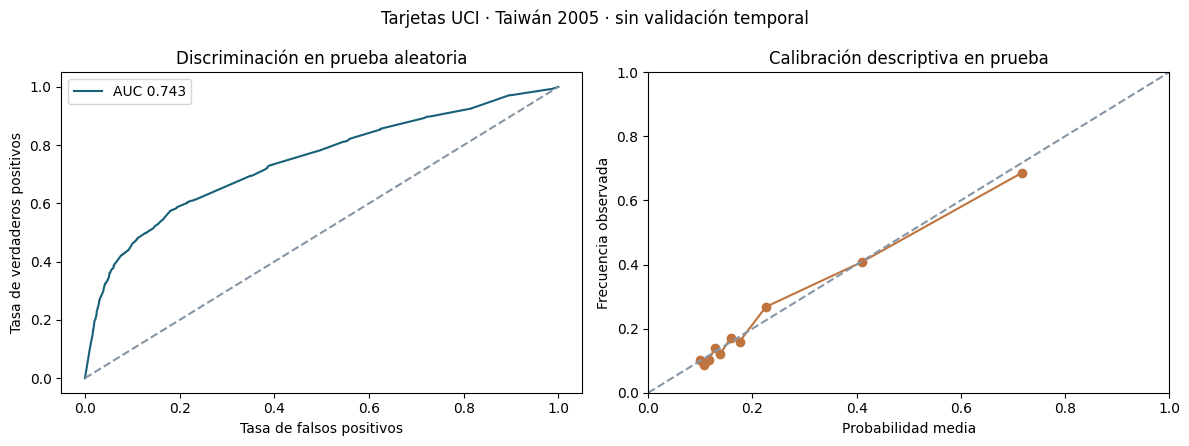

In [4]:
fig,axs=plt.subplots(1,2,figsize=(12,4.5));axs[0].plot(fpr,tpr,color='#176078',label=f'AUC {auc:.3f}');axs[0].plot([0,1],[0,1],color='#8796a5',ls='--');axs[0].set(title='Discriminación en prueba aleatoria',xlabel='Tasa de falsos positivos',ylabel='Tasa de verdaderos positivos');axs[0].legend()
axs[1].plot(calibration.probabilidad_media,calibration.tasa_observada,'o-',color='#bf7440');axs[1].plot([0,1],[0,1],ls='--',color='#8796a5');axs[1].set(xlim=(0,1),ylim=(0,1),title='Calibración descriptiva en prueba',xlabel='Probabilidad media',ylabel='Frecuencia observada');fig.suptitle('Tarjetas UCI · Taiwán 2005 · sin validación temporal',fontsize=12);plt.tight_layout();plt.show()

## Comparador y estabilidad por remuestreo
Se ajusta una logística con variables numéricas estandarizadas en el mismo entrenamiento. Es un comparador predictivo, no un scorecard de originación. La comparación es exploratoria: no sustituye una selección validada en un conjunto independiente. Calculamos 500 réplicas bootstrap pareadas sobre la prueba, con semilla fija; el intervalo refleja variación de la muestra retenida **condicionada a los modelos ya ajustados**. No incluye variación por reentrenamiento, selección de variables ni cambio de cohorte.

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
challenger=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000,random_state=42))
challenger.fit(train[features],train[target]); prob_raw=challenger.predict_proba(test[features])[:,1]
comparison=pd.DataFrame([{'modelo':'WoE + logística','AUC':roc_auc_score(y,prob),'Brier':brier_score_loss(y,prob)}, {'modelo':'Logística estandarizada','AUC':roc_auc_score(y,prob_raw),'Brier':brier_score_loss(y,prob_raw)}])
display(comparison.round(4))
rng=np.random.default_rng(20261112); diferencias=[]; auc_woe=[]
for _ in range(500):
    ix=rng.integers(0,len(y),len(y))
    if np.unique(y[ix]).size<2: continue
    a=roc_auc_score(y[ix],prob[ix]); b=roc_auc_score(y[ix],prob_raw[ix]);auc_woe.append(a);diferencias.append(a-b)
assert len(diferencias)>=490
print('AUC WoE, intervalo bootstrap percentil 95 %:',np.round(np.quantile(auc_woe,[.025,.975]),4))
print('Diferencia de AUC (WoE − logística), intervalo 95 %:',np.round(np.quantile(diferencias,[.025,.975]),4))

,modelo,AUC,Brier
0,WoE + logística,0.7432,0.1399
1,Logística estandarizada,0.7067,0.1470


AUC WoE, intervalo bootstrap percentil 95 %: [0.7294 0.7582]
Diferencia de AUC (WoE − logística), intervalo 95 %: [0.0277 0.0463]


## Puntos de operación ilustrativos
Para tres umbrales definidos antes de observar esta tabla, mostramos sensibilidad y proporción de alertas. La tabla ayuda a discutir capacidad de revisión; no optimiza un punto de corte ni incorpora costos, recuperación, rechazos o revisión humana. No debe utilizarse como política de aprobación.

In [6]:
oper=[]
for threshold in [.2,.3,.5]:
    flag=prob>=threshold;tp=int(((y==1)&flag).sum());fp=int(((y==0)&flag).sum());fn=int(((y==1)&~flag).sum())
    oper.append({'umbral':threshold,'alertas':int(flag.sum()),'fraccion_alertas':flag.mean(),'sensibilidad':tp/(tp+fn) if tp+fn else np.nan,'precision_alertas':tp/(tp+fp) if tp+fp else np.nan})
pd.DataFrame(oper).round(4)

,umbral,alertas,fraccion_alertas,sensibilidad,precision_alertas
0,0.2,2008,0.2677,0.5738,0.4741
1,0.3,1353,0.1804,0.4623,0.5669
2,0.5,944,0.1259,0.3725,0.6547


## Limitaciones y gobierno
El test comparte periodo y población con entrenamiento; no hay corte de originación ni pruebas de estabilidad temporal. Los historiales de pago no se conocen necesariamente al originar; no utilizar este modelo como score de onboarding. No se incorpora política de aceptación, rechazados, cambios de exposición, costos, calibración por población o revisión de equidad. La etiqueta del dataset y sus restricciones se conservan; no es EVER >30 MOB 3. La aplicación requiere revisión independiente, permisos y datos institucionales adecuados antes de cualquier decisión.